# Implied acuity distributions vs the recorded visits

Fitted model: `fit_person_records.py`, variant `bin_indep`. Eyes share one latent acuity per person. Binocular readings have their own independent distribution, so nothing is assumed about gain or summation. Monocular and binocular readings share one recording rule, with a separate bare-record window at each line, and the only link between them is the visit's recording style. Curves use posterior means; posterior SDs on the mean and SD are under 0.007, so a band would be barely visible.

**Empirical** means the numbers recorded at each visit: ages 20-50, idiff <= 0.1, the same rows the model used. Recorded logMAR is discrete, so tall bars at 20/15, 20/20 and 20/25 are bare records stacked on one value. The model says those people are really spread out around the line, so the bars and curves are not expected to match bin by bin. The cumulative plots are the fairer comparison.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import fit_person_records as fpr
from fit_ding_sperling_decimal_pymc import load_all_df

IDIFF_MAX = 0.1
SURFACE, INK, MUTED, GRID_INK = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
EMPIRICAL, MODEL = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID_INK, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_INK,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11,
    "figure.dpi": 110,
})

idata = az.from_netcdf("person_records_bin_indep.nc")
p = fpr.post_means(idata)
az.summary(idata, var_names=["mean_logmar", "sd_logmar", "sigma_eye", "m_bin", "s_bin", "w_poor_bin", "gap_bin", "s_poor_bin",
                             "p_line_style", "h15", "h20_better", "h20_worse", "h25", "b1", "b2", "b3", "c1", "c2"],
                  round_to=4)[
    ["mean", "sd", "hdi_3%", "hdi_97%", "r_hat"]]

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


,mean,sd,hdi_3%,hdi_97%,r_hat
mean_logmar,-0.0475,0.0051,-0.0569,-0.0376,1.0125
sd_logmar,0.0716,0.0026,0.0668,0.0766,1.0067
sigma_eye,0.0220,0.0009,0.0204,0.0237,1.0083
m_bin,-0.0980,0.0062,-0.1095,-0.0866,1.0113
s_bin,0.0878,0.0036,0.0808,0.0945,1.0056
w_poor_bin,0.0458,0.0051,0.0384,0.0500,1.0035
gap_bin,0.1070,0.0223,0.1000,0.1141,1.0045
s_poor_bin,0.0334,0.0190,0.0300,0.0366,1.0038
p_line_style,0.2675,0.0091,0.2504,0.2848,1.0010
h15,0.0198,0.0066,0.0069,0.0313,1.0124


In [2]:
# Empirical records, one row per visit, using the same rows as the fit.
df = load_all_df()
df = df[df["age"].between(fpr.AGE_LO, fpr.AGE_HI) & (df["idiff"] <= IDIFF_MAX)]
cats = pd.DataFrame({"L": fpr.categorise(df["raw_left"]), "R": fpr.categorise(df["raw_right"]),
                     "B": fpr.categorise(df["raw_both"])})
keep = cats.notna().all(axis=1)
df, cats = df[keep], cats[keep].astype(int)
n_visits = len(df)

empirical = {
    "Left eye": df["left"].to_numpy(),
    "Right eye": df["right"].to_numpy(),
    "Better eye": df["logmar_better"].to_numpy(),
    "Binocular": df["logmar_binocular"].to_numpy(),
    "Mean of left and right": ((df["left"] + df["right"]) / 2).to_numpy(),
}

# Implied underlying distributions: draws of latent person acuity and the unrounded readings.
rng = np.random.default_rng(1)
N = 2_000_000
poor = rng.random(N) < p["w_poor"]
mu = np.where(poor, rng.normal(p["mean_logmar"] + p["gap"], p["s_poor"], N),
              rng.normal(p["mean_logmar"], p["sd_logmar"], N))
left = mu + rng.normal(0, p["sigma_eye"], N)
right = mu + rng.normal(0, p["sigma_eye"], N)
binocular_draws = fpr.independent_binocular(p, rng, N)
low = rng.random(N) < p["w_poor_bin"]
binocular_draws[low] = rng.normal(p["m_bin"] + p["gap_bin"], p["s_poor_bin"], low.sum())
implied = {
    "Left eye": left,
    "Right eye": right,
    "Better eye": np.minimum(left, right),
    "Binocular": binocular_draws,
    "Mean of left and right": mu,
}
print(f"{n_visits} visits")
pd.DataFrame({
    "empirical mean": {k: v.mean() for k, v in empirical.items()},
    "implied mean": {k: v.mean() for k, v in implied.items()},
    "empirical median": {k: np.median(v) for k, v in empirical.items()},
    "implied median": {k: np.median(v) for k, v in implied.items()},
    "empirical SD": {k: v.std(ddof=1) for k, v in empirical.items()},
    "implied SD": {k: v.std(ddof=1) for k, v in implied.items()},
}).round(3)

sc file: kept 117 of 198 rows
nonint_age file: kept 132 of 133 rows (dash/dot ages with valid acuity)
Rows used: 7085 of 7085 (no logMAR cutoff needed)
3279 visits


,empirical mean,implied mean,empirical median,implied median,empirical SD,implied SD
Left eye,-0.026,-0.046,0.00,-0.047,0.084,0.082
Right eye,-0.027,-0.046,0.00,-0.047,0.085,0.082
Better eye,-0.034,-0.058,0.00,-0.059,0.082,0.081
Binocular,-0.051,-0.093,-0.04,-0.093,0.081,0.089
Mean of left and right,-0.026,-0.046,0.00,-0.047,0.083,0.079


## Empirical counts with the implied distribution on top

Bars are recorded values per visit, in 0.02 logMAR bins (one letter). The curve is the implied underlying distribution before recording, scaled to expected visits per bin. `Mean of left and right` is compared with the latent person acuity, which is the closest thing the data have to it. Records beyond 0.35 logMAR are off the plot but counted.

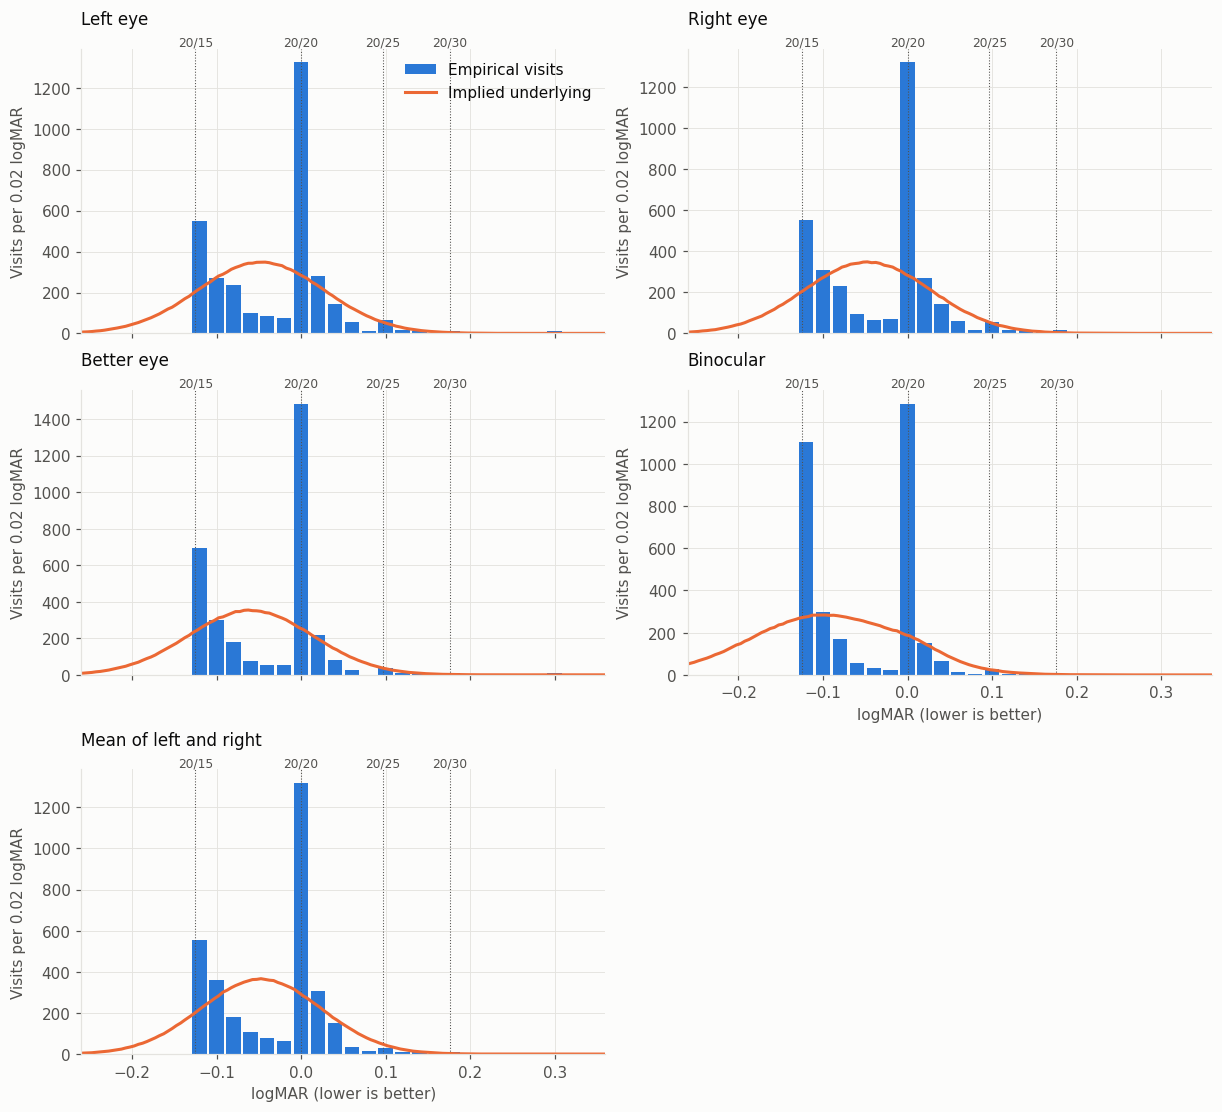

In [3]:
XLIM = (-0.26, 0.36)
LINES = {"20/15": fpr.L15, "20/20": fpr.L20, "20/25": fpr.L25, "20/30": fpr.L30}
BIN = 0.02
edges_ = np.arange(-0.31, 0.41, BIN)   # bins centred on 0, so records sit on their lines
fine = np.arange(-0.4, 0.5, 0.005)


def mark_lines(ax, labels=False):
    top = ax.get_ylim()[1]
    for name, x in LINES.items():
        ax.axvline(x, color=MUTED, lw=0.7, ls=":", zorder=1)
        if labels:
            ax.text(x, top, name, ha="center", va="bottom", fontsize=8, color=MUTED)


names = list(empirical)
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True, layout="constrained")
for ax, name in zip(axes.ravel(), names):
    ax.hist(empirical[name], bins=edges_, color=EMPIRICAL, rwidth=0.85, label="Empirical visits")
    dens, e = np.histogram(implied[name], bins=fine, density=True)
    ax.plot((e[1:] + e[:-1]) / 2, dens * n_visits * BIN, color=MODEL, lw=2, label="Implied underlying")
    ax.set_xlim(XLIM)
    ax.set_title(name, loc="left", pad=16)
    ax.set_ylabel("Visits per 0.02 logMAR")
    mark_lines(ax, labels=True)
axes[0, 0].legend(frameon=False, loc="upper right")
axes[2, 1].set_visible(False)
axes[1, 1].tick_params(labelbottom=True)
axes[2, 0].set_xlabel("logMAR (lower is better)")
axes[1, 1].set_xlabel("logMAR (lower is better)")
plt.show()

## Cumulative comparison

This removes the binning problem. Bare records pile up at a line, so the empirical curve jumps there. If bare records are people spread around the line, the jump should straddle the implied curve, starting below it and ending above it. That's what happens at 20/20.

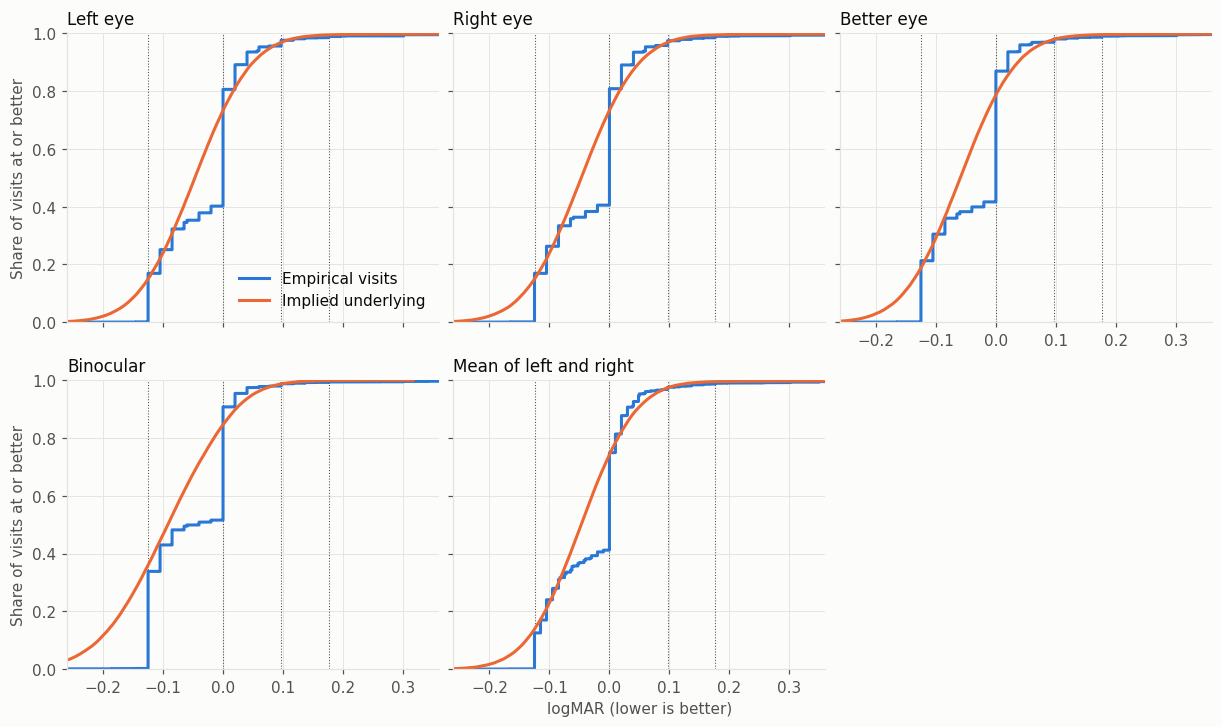

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharex=True, sharey=True, layout="constrained")
for ax, name in zip(axes.ravel(), names):
    x = np.sort(empirical[name])
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=EMPIRICAL, lw=2, label="Empirical visits")
    z = np.sort(implied[name][::20])
    ax.plot(z, np.arange(1, len(z) + 1) / len(z), color=MODEL, lw=2, label="Implied underlying")
    ax.set_xlim(XLIM)
    ax.set_ylim(0, 1.0)
    ax.set_title(name, loc="left")
    mark_lines(ax)
axes[0, 0].legend(frameon=False, loc="lower right")
axes[0, 0].set_ylabel("Share of visits at or better")
axes[1, 0].set_ylabel("Share of visits at or better")
axes[1, 1].set_xlabel("logMAR (lower is better)")
axes[1, 2].set_visible(False)
axes[0, 2].tick_params(labelbottom=True)
plt.show()

## Where each record type comes from

The implied distribution before recording, split by the record the model expects it to produce. Each band's area is that record's expected share. Both figures use the same recording rule, on the same axes, so the differences come from the distributions. The dashed lines mark the mean and ±1 SD of the main Normal. In the binocular figure, about 4.6% of readings sit in a small extra component near 20/20. It isn't poor vision: a single Normal can't produce enough mass there, and the fit can't yet say whether that reflects a non-Normal binocular shape or a small rule difference. The lower panels zoom in on 20/25.

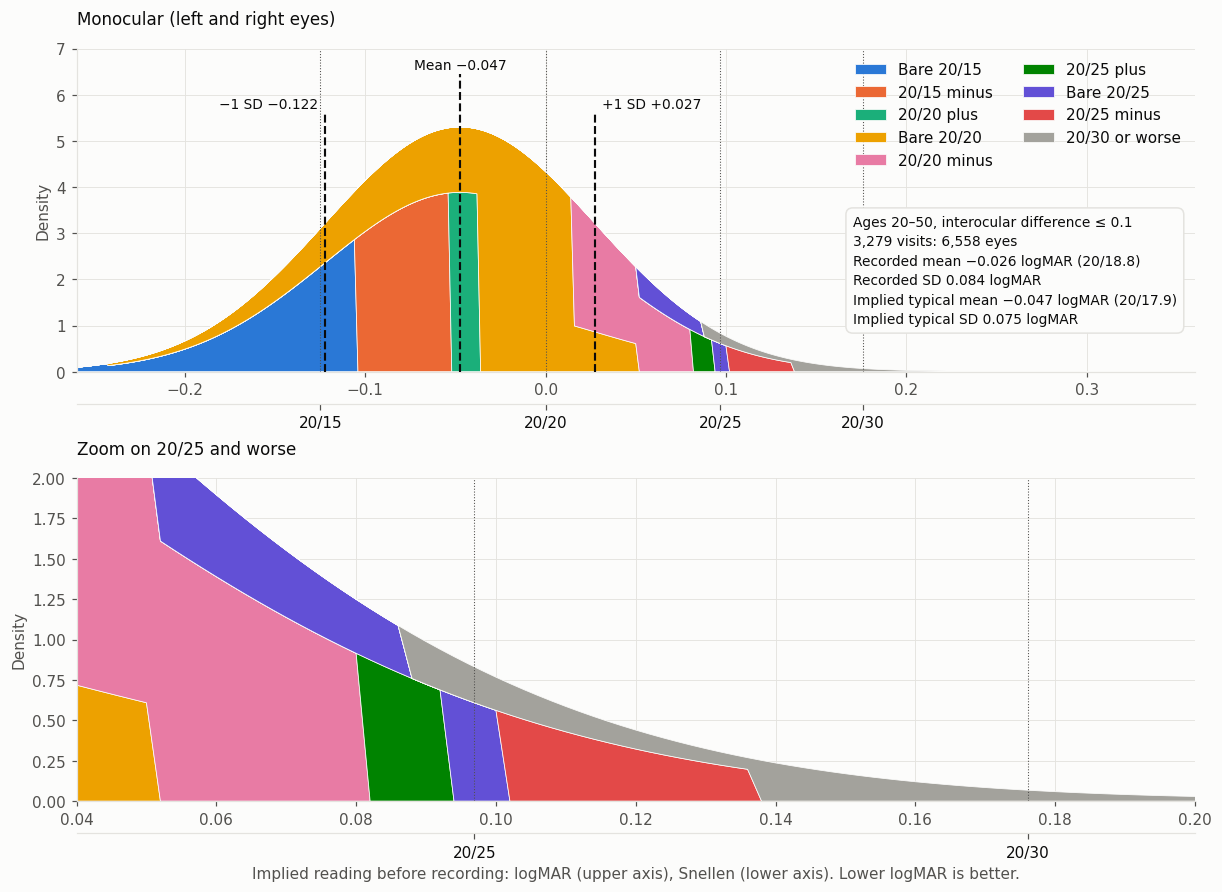

In [5]:
y = np.arange(-0.35, 0.4, 0.002)
normal = lambda x, m, s: np.exp(-0.5 * ((x - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
labels = ["Bare 20/15", "20/15 minus", "20/20 plus", "Bare 20/20", "20/20 minus",
          "20/25 plus", "Bare 20/25", "20/25 minus", "20/30 or worse"]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
          "#008300", "#6250d6", "#e34948", "#a3a29c"]
snellen = lambda logmar: f"20/{20 * 10 ** logmar:.1f}"
YMAX = 7.0


def snellen_axis(ax, names, label=None):
    # Second x-axis below the logMAR axis, with a tick at each Snellen line.
    sec = ax.secondary_xaxis(-0.1)
    sec.set_xticks([LINES[n] for n in names], names)
    sec.tick_params(axis="x", length=4, labelcolor=INK)
    if label:
        sec.set_xlabel(label)


def record_types(title, mean_typ, sd_typ, w_other, mean_other, sd_other, recorded, count_line, stem):
    dens = (1 - w_other) * normal(y, mean_typ, sd_typ) + w_other * normal(y, mean_other, sd_other)
    line_lo, line_hi, let_lo, let_hi = fpr.edges(p, np.array)
    pi = p["p_line_style"]
    by_cat = np.array([dens * (pi * ((y >= line_lo[k]) & (y < line_hi[k]))
                               + (1 - pi) * ((y >= let_lo[k]) & (y < let_hi[k])))
                       for k in range(len(fpr.CATS))])

    fig, axes = plt.subplots(2, 1, figsize=(11, 8), layout="constrained")
    for ax, xlim in zip(axes, [XLIM, (0.04, 0.2)]):
        ax.stackplot(y, by_cat, labels=labels, colors=colors, edgecolor=SURFACE, linewidth=0.5)
        ax.set_xlim(xlim)
        ax.set_ylabel("Density")
    axes[0].set_ylim(0, YMAX)
    axes[1].set_ylim(0, 2.0)
    axes[0].set_title(title, loc="left", pad=16)
    axes[1].set_title("Zoom on 20/25 and worse", loc="left", pad=16)
    label = "Implied reading before recording: logMAR (upper axis), Snellen (lower axis). Lower logMAR is better."
    snellen_axis(axes[0], list(LINES))
    snellen_axis(axes[1], ["20/25", "20/30"], label)
    axes[0].legend(frameon=False, ncol=2, loc="upper right")
    mark_lines(axes[0])
    for name in ["20/25", "20/30"]:
        axes[1].axvline(LINES[name], color=MUTED, lw=0.7, ls=":", zorder=4)

    for x, top, text, ha, dx in [(mean_typ, 6.45, f"Mean {mean_typ:+.3f}", "center", 0),
                                 (mean_typ - sd_typ, 5.6, f"−1 SD {mean_typ - sd_typ:+.3f}", "right", -0.004),
                                 (mean_typ + sd_typ, 5.6, f"+1 SD {mean_typ + sd_typ:+.3f}", "left", 0.004)]:
        axes[0].vlines(x, 0, top, color=INK, lw=1.4, ls="--", zorder=5)
        axes[0].text(x + dx, top + 0.05, text.replace("-", "−"), ha=ha, va="bottom", fontsize=9, color=INK)

    summary = "\n".join([
        f"Ages {fpr.AGE_LO}–{fpr.AGE_HI}, interocular difference ≤ {IDIFF_MAX}",
        count_line,
        f"Recorded mean {recorded.mean():+.3f} logMAR ({snellen(recorded.mean())})",
        f"Recorded SD {recorded.std(ddof=1):.3f} logMAR",
        f"Implied typical mean {mean_typ:+.3f} logMAR ({snellen(mean_typ)})",
        f"Implied typical SD {sd_typ:.3f} logMAR",
    ]).replace("-", "−")
    axes[0].text(0.35, 3.4, summary, va="top", ha="right", multialignment="left", fontsize=9, color=INK,
                 linespacing=1.5, zorder=6,
                 bbox=dict(facecolor=SURFACE, edgecolor=GRID_INK, boxstyle="round,pad=0.5"))
    fig.savefig(f"{stem}.png", dpi=300)
    fig.savefig(f"{stem}.pdf")
    plt.show()


eyes = np.r_[empirical["Left eye"], empirical["Right eye"]]
record_types("Monocular (left and right eyes)", p["mean_logmar"], np.hypot(p["sd_logmar"], p["sigma_eye"]),
             p["w_poor"], p["mean_logmar"] + p["gap"], np.hypot(p["s_poor"], p["sigma_eye"]), eyes,
             f"{n_visits:,} visits: {len(eyes):,} eyes", "record_types_monocular")

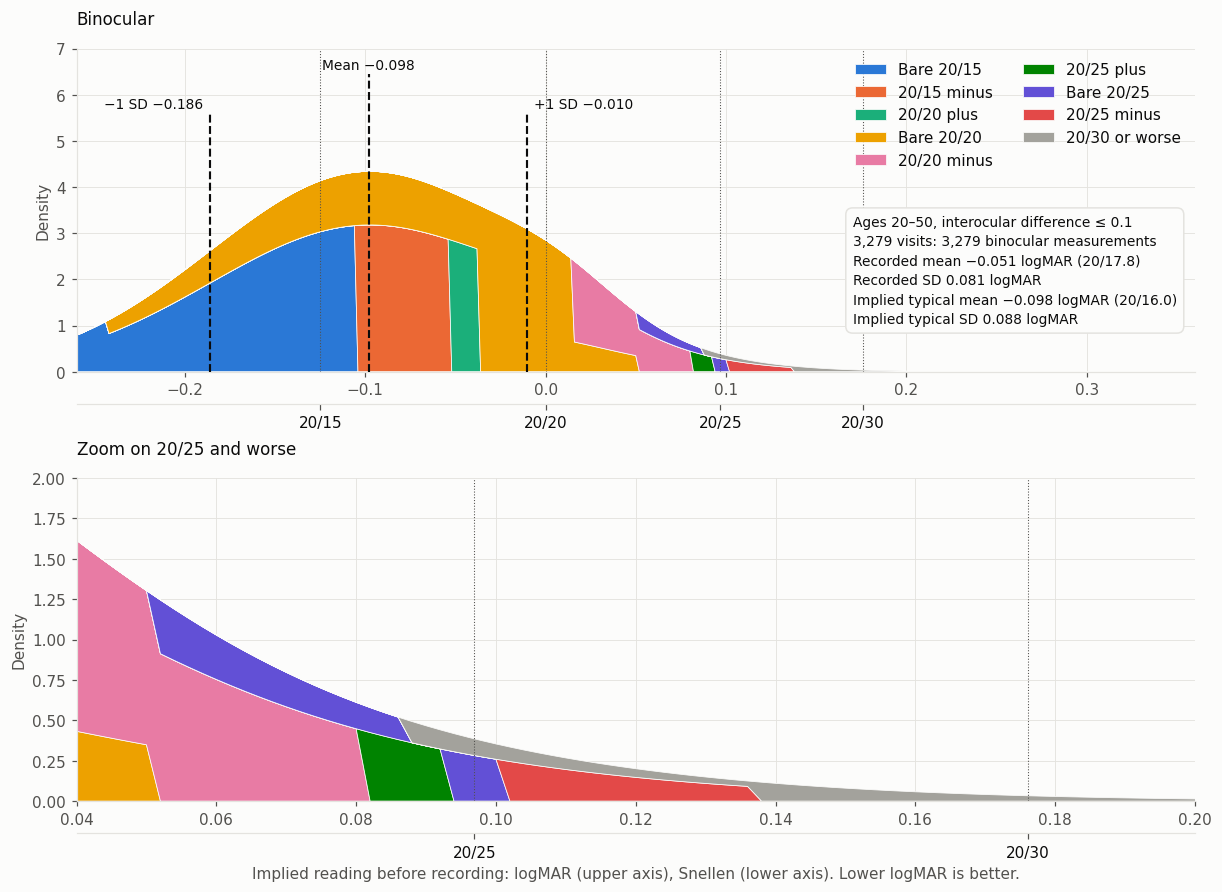

In [6]:
binocular = empirical["Binocular"]
record_types("Binocular", p["m_bin"], p["s_bin"], p["w_poor_bin"], p["m_bin"] + p["gap_bin"], p["s_poor_bin"],
             binocular, f"{n_visits:,} visits: {len(binocular):,} binocular measurements",
             "record_types_binocular")

### What a bare record covers at each line

Windows are absolute logMAR, from the same fit. One rule covers monocular and binocular readings. `NaN` means the window is open on that side, because the chart stops at 20/15.

In [7]:
def windows(r):
    return pd.DataFrame({
        "Letter visits, from": [None, -r["h20_better"], fpr.L25 - r["h25"]],
        "Letter visits, to": [fpr.L15 + r["h_bare"], r["h20_worse"], fpr.L25 + r["h25"]],
        "Line-only visits, from": [None, r["b1"], r["b2"]],
        "Line-only visits, to": [r["b1"], r["b2"], r["b3"]],
    }, index=["Bare 20/15", "Bare 20/20", "Bare 20/25"]).astype(float).round(3)


windows(p)

,"Letter visits, from","Letter visits, to","Line-only visits, from","Line-only visits, to"
Bare 20/15,NaN,-0.105,NaN,-0.244
Bare 20/20,-0.038,0.015,-0.244,0.051
Bare 20/25,0.092,0.102,0.051,0.086


## Empirical vs model record counts

Counts of each record type, compared with what the fitted model produces after recording. This is the direct test of the fit, and it shows the remaining misfit.

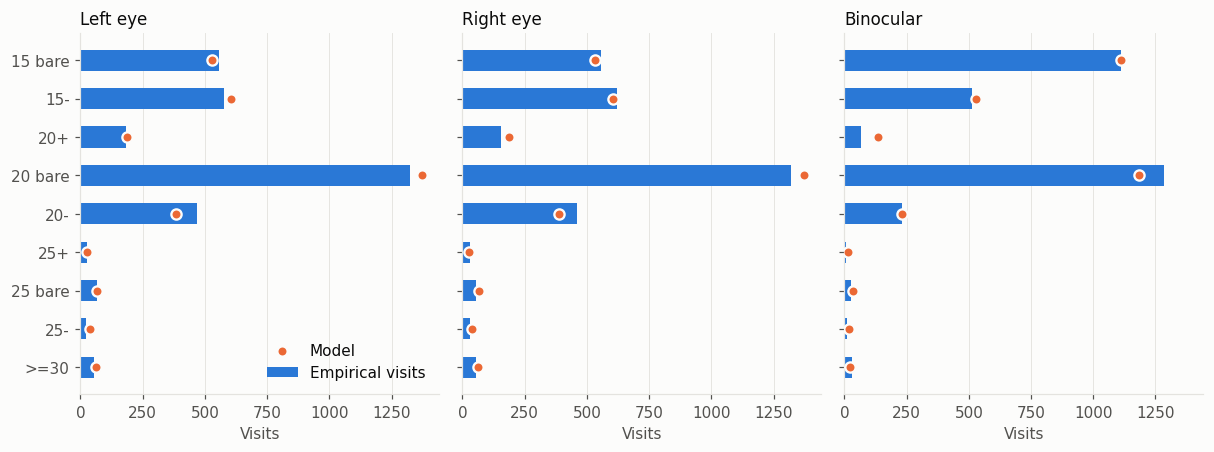

,L empirical,L model,R empirical,R model,B empirical,B model
15 bare,555,529,555,531,1110,1111
15-,578,606,620,605,514,530
20+,185,188,154,188,68,134
20 bare,1325,1373,1322,1371,1285,1184
20-,467,385,461,387,231,231
25+,25,28,29,28,6,13
25 bare,65,68,54,67,26,35
25-,23,39,29,40,10,18
>=30,56,62,55,62,29,23


In [8]:
sim = fpr.simulate(p, 400_000, True)
scale = n_visits / len(sim)
k = range(len(fpr.CATS))
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharex=True, layout="constrained")
rows = []
for ax, (col, title) in zip(axes, [("L", "Left eye"), ("R", "Right eye"), ("B", "Binocular")]):
    o = cats[col].value_counts().reindex(k, fill_value=0).to_numpy()
    s = sim[col].value_counts().reindex(k, fill_value=0).to_numpy() * scale
    pos = np.arange(len(fpr.CATS))
    ax.barh(pos, o, height=0.55, color=EMPIRICAL, label="Empirical visits")
    ax.scatter(s, pos, s=45, color=MODEL, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="Model")
    ax.set_yticks(pos, fpr.CATS if col == "L" else [""] * len(pos))
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Visits")
    rows.append(pd.Series(o, index=fpr.CATS, name=f"{col} empirical"))
    rows.append(pd.Series(s.round(0).astype(int), index=fpr.CATS, name=f"{col} model"))
axes[0].legend(frameon=False, loc="lower right")
plt.show()
pd.concat(rows, axis=1)

## Posteriors of every parameter

Each panel is a parameter's posterior from all 10 chains. Dashed lines mark the limits set in the fit, drawn only where the posterior comes close to one. A posterior pressed against a limit means the data want to go further, so read that value as a bound and not an estimate. `b3`, `c1` and `c2` have no fixed limit of their own.

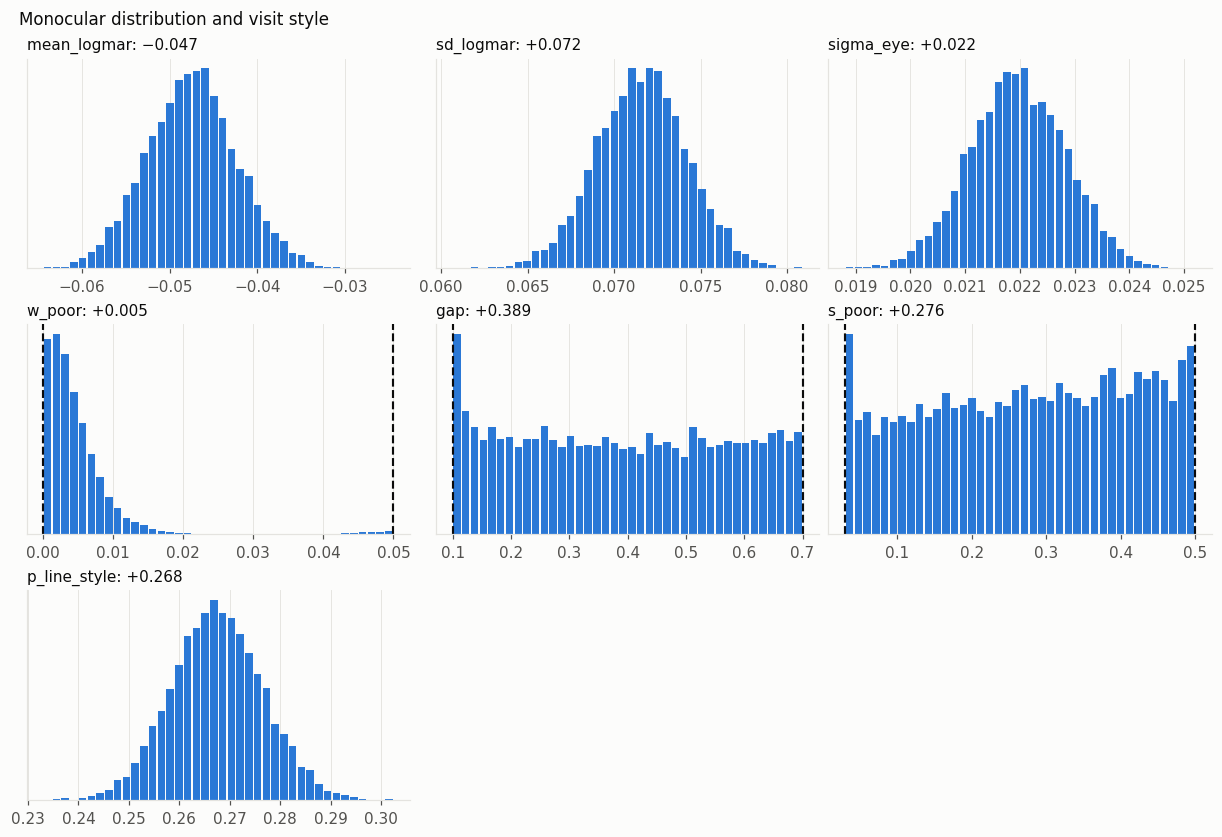

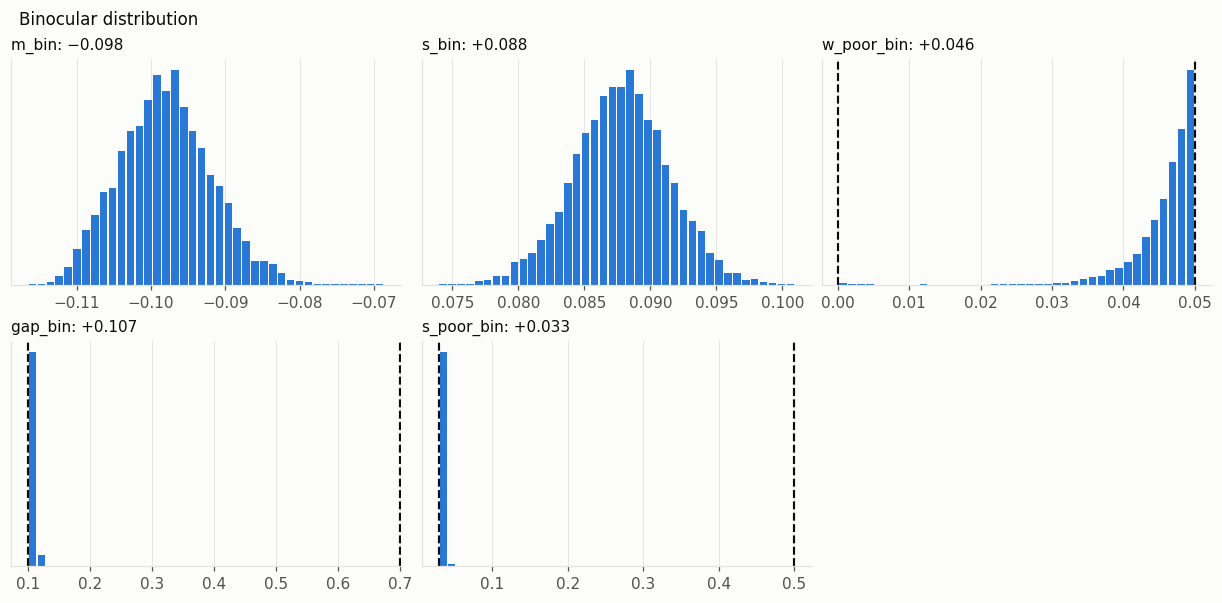

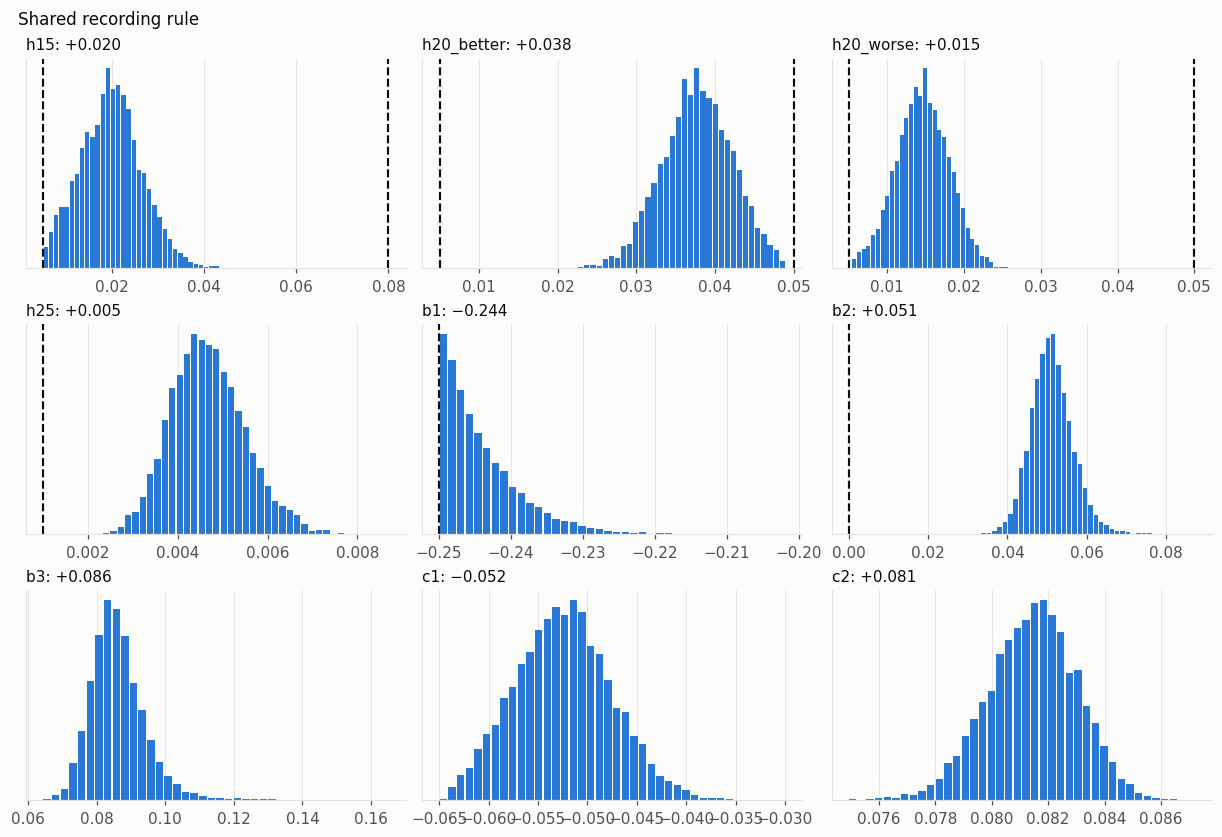

In [9]:
LIMITS = {"mean_logmar": (-0.25, 0.05), "sd_logmar": (0.01, 0.2), "sigma_eye": (0.005, 0.15),
          "m_bin": (-0.25, 0.05), "s_bin": (0.01, 0.2), "w_poor_bin": (0, 0.05), "gap_bin": (0.1, 0.7),
          "s_poor_bin": (0.03, 0.5), "p_line_style": (0, 1), "w_poor": (0, 0.05), "gap": (0.1, 0.7),
          "s_poor": (0.03, 0.5), "h15": (0.005, 0.08), "h20_better": (0.005, 0.05),
          "h20_worse": (0.005, 0.05), "h25": (0.001, 0.04), "b1": (-0.25, 0), "b2": (0, 0.15)}

draws = lambda name, data=idata: data.posterior[name].values.ravel()


def posterior_grid(title, names):
    fig, axes = plt.subplots(3, 3, figsize=(11, 7.5), layout="constrained")
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    for ax, name in zip(axes.ravel(), names):
        x = draws(name)
        ax.hist(x, bins=40, color=EMPIRICAL, rwidth=0.85)
        ax.set_title(f"{name}: {x.mean():+.3f}".replace("-", "−"), loc="left", fontsize=10)
        ax.set_yticks([])
        ax.grid(axis="y", visible=False)
        span = x.max() - x.min()
        for limit in LIMITS.get(name, ()):
            if x.min() - span <= limit <= x.max() + span:
                ax.axvline(limit, color=INK, lw=1.4, ls="--")
    for ax in axes.ravel()[len(names):]:
        ax.set_visible(False)
    plt.show()


posterior_grid("Monocular distribution and visit style",
               ["mean_logmar", "sd_logmar", "sigma_eye", "w_poor", "gap", "s_poor", "p_line_style"])
posterior_grid("Binocular distribution", ["m_bin", "s_bin", "w_poor_bin", "gap_bin", "s_poor_bin"])
posterior_grid("Shared recording rule",
               ["h15", "h20_better", "h20_worse", "h25", "b1", "b2", "b3", "c1", "c2"])

## Trade-offs between parameters

Each dot is one posterior draw, and the upper triangle gives the correlation. Strong correlations mean the data fix a combination of the two parameters better than either alone.

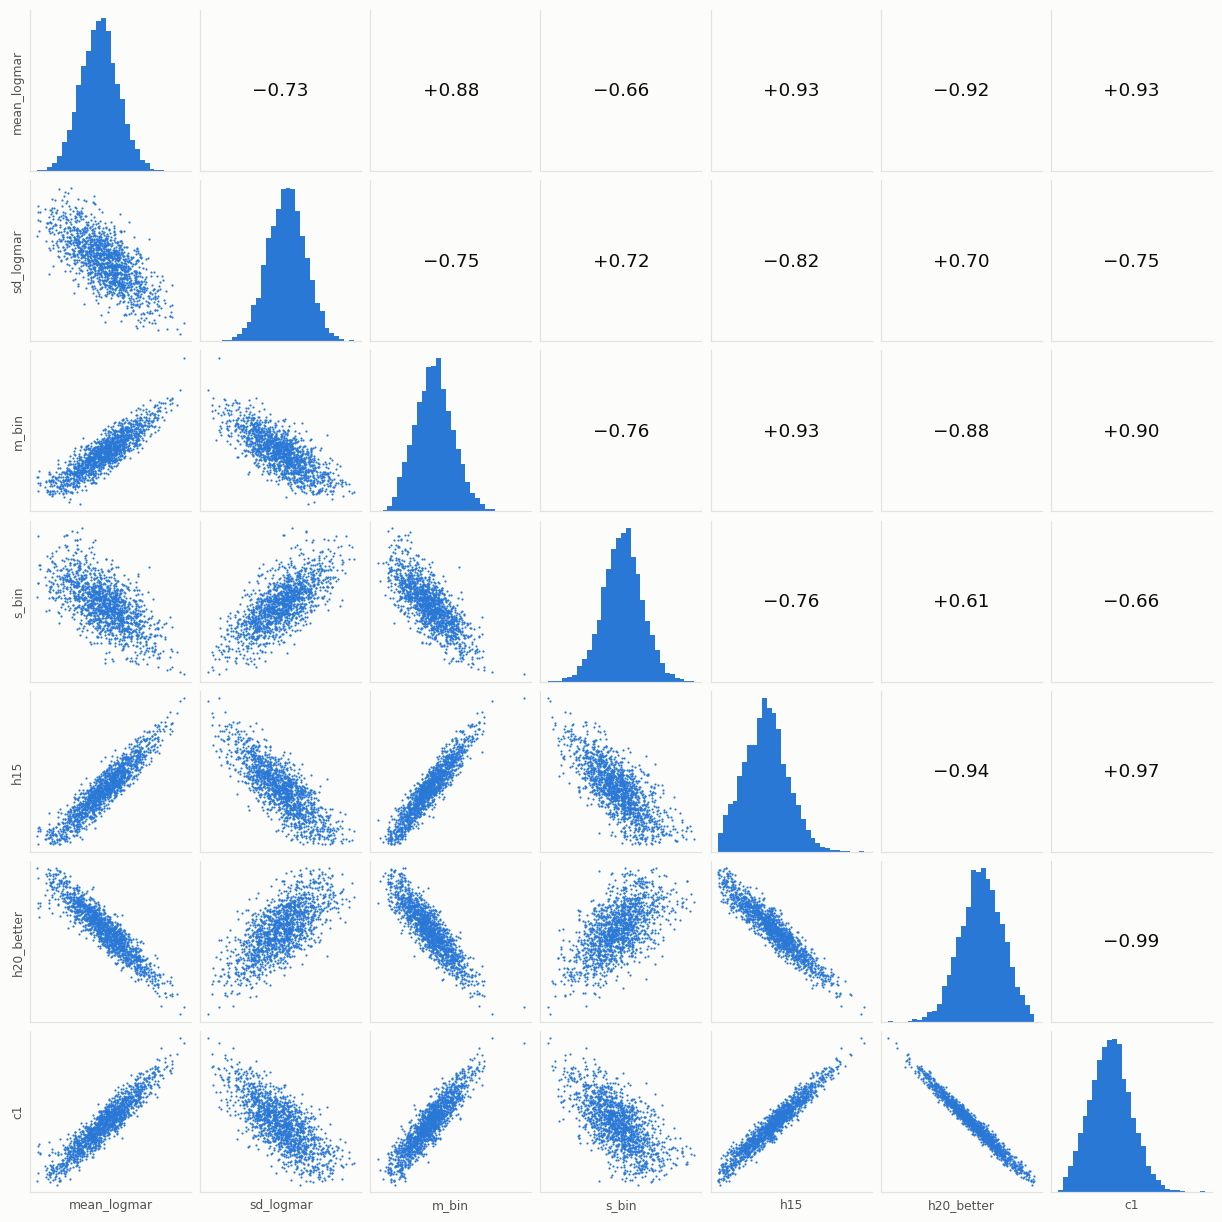

In [10]:
pair_names = ["mean_logmar", "sd_logmar", "m_bin", "s_bin", "h15", "h20_better", "c1"]
pair_rng = np.random.default_rng(1)
pick = pair_rng.choice(len(draws("mean_logmar")), 1500, replace=False)
k = len(pair_names)
fig, axes = plt.subplots(k, k, figsize=(11, 11), layout="constrained")
for i, a in enumerate(pair_names):
    for j, b in enumerate(pair_names):
        ax = axes[i, j]
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        if i == j:
            ax.hist(draws(a), bins=30, color=EMPIRICAL)
        elif i > j:
            ax.scatter(draws(b)[pick], draws(a)[pick], s=2, color=EMPIRICAL, linewidths=0)
        else:
            r = np.corrcoef(draws(a), draws(b))[0, 1]
            ax.text(0.5, 0.5, f"{r:+.2f}".replace("-", "−"), transform=ax.transAxes, ha="center",
                    va="center", fontsize=12 if abs(r) >= 0.5 else 9, color=INK if abs(r) >= 0.5 else MUTED)
        if j == 0:
            ax.set_ylabel(a, fontsize=8)
        if i == k - 1:
            ax.set_xlabel(b, fontsize=8)
plt.show()

## Posteriors of the implied values

The values that matter most, computed for every draw. Blue is the reference fit with one shared rule. Orange is the same independent-binocular model with a separate binocular rule. The width of each posterior is the uncertainty within a fit, and the gap between the colours is how much the answer depends on the recording rule. Binocular values are for the main Normal, leaving out the small component near 20/20. Your target (−0.086, 0.095) is the dashed line.

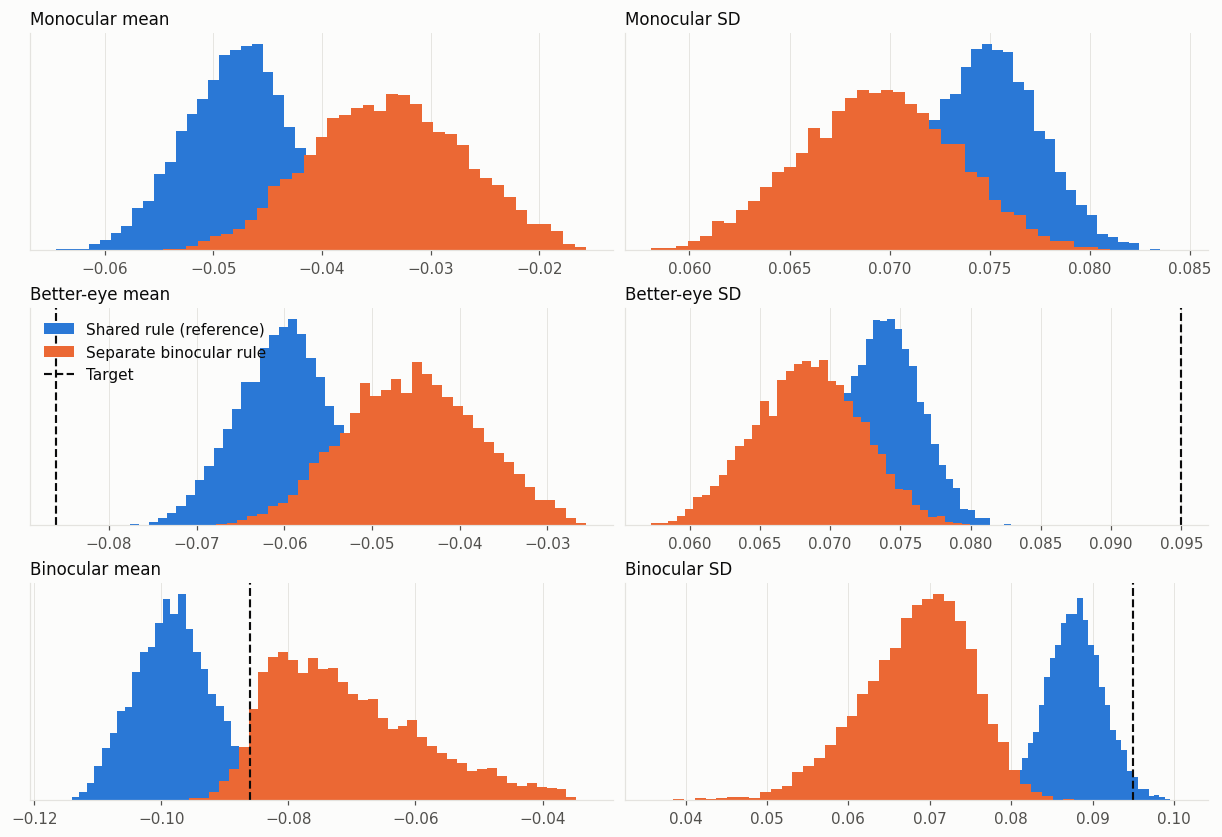

,Reference mean,Reference 3%,Reference 97%,Separate-rule mean
Monocular mean,-0.047,-0.057,-0.038,-0.034
Monocular SD,0.075,0.070,0.080,0.069
Better-eye mean,-0.060,-0.070,-0.049,-0.045
Better-eye SD,0.074,0.069,0.079,0.068
Binocular mean,-0.098,-0.109,-0.086,-0.071
Binocular SD,0.088,0.081,0.095,0.068


In [11]:
separate = az.from_netcdf("person_records_bin_indep_sep.nc")


def implied_values(data):
    m, s = draws("mean_logmar", data), draws("sd_logmar", data)
    se = draws("sigma_eye", data)
    return {
        "Monocular mean": m, "Monocular SD": np.hypot(s, se),
        "Better-eye mean": m - se / np.sqrt(np.pi),
        "Better-eye SD": np.sqrt(s ** 2 + se ** 2 * (1 - 1 / np.pi)),
        "Binocular mean": draws("m_bin", data), "Binocular SD": draws("s_bin", data),
    }


ref_values, separate_values = implied_values(idata), implied_values(separate)
targets = {"Better-eye mean": -0.086, "Better-eye SD": 0.095, "Binocular mean": -0.086, "Binocular SD": 0.095}
fig, axes = plt.subplots(3, 2, figsize=(11, 7.5), layout="constrained")
for ax, name in zip(axes.ravel(), ref_values):
    ax.hist(ref_values[name], bins=40, color=EMPIRICAL, label="Shared rule (reference)")
    ax.hist(separate_values[name], bins=40, color=MODEL, label="Separate binocular rule")
    if name in targets:
        ax.axvline(targets[name], color=INK, lw=1.4, ls="--", label="Target")
    ax.set_title(name, loc="left")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[1, 0].legend(frameon=False, loc="upper left")
plt.show()

pd.DataFrame({"Reference mean": {k: v.mean() for k, v in ref_values.items()},
              "Reference 3%": {k: np.percentile(v, 3) for k, v in ref_values.items()},
              "Reference 97%": {k: np.percentile(v, 97) for k, v in ref_values.items()},
              "Separate-rule mean": {k: v.mean() for k, v in separate_values.items()}}).round(3)

## What to take from this

- The implied curves are smooth where the records are lumpy. Most of the lumps are bare records at 20/15 and 20/20.
- Better than 20/15 is implied, not measured. The chart appears to stop there, so that tail comes from the Normal assumption.
- The bare-record rule differs by line. The 20/25 windows rest on few records.
- Under one shared rule, binocular `20/20 plus` is over-predicted and a small extra component is needed near 20/20. A non-Normal binocular shape and a small rule difference aren't separated yet.
- The population estimates depend on the recording model. The implied-value posteriors show that the gap between fits is larger than the uncertainty within either.